In [1]:
%pip install -q --disable-pip-version-check numpy==2.3.5 pandas==3.0.1 scikit-learn==1.8.0 xgboost==3.1.3 shap==0.50.0 pyproj==3.7.2 scipy==1.18.1 matplotlib==3.10.8 psutil==7.2.2

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import hashlib
import time
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import psutil
from IPython.display import display
from pyproj import Transformer
from scipy.spatial import cKDTree
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, ParameterSampler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

In [6]:
data_folder = Path.cwd()
output_folder = Path.cwd() / 'astana_student_outputs'
output_folder.mkdir(exist_ok=True)
start_time = time.perf_counter()
raw_data = pd.read_csv(data_folder / 'krisha_data_raw.csv')
prepared_data = pd.read_csv(data_folder / 'astana_real_estate_dataset.csv')
print(raw_data.shape)
display(raw_data.head())

(5003, 23)


,url,title,price,Балкон,Балкон остеклён,Безопасность,Бывшее общежитие,Возможен обмен,Высота потолков,Год постройки,...,Интернет,Квартира меблирована,Парковка,Площадь,Пол,Санузел,Состояние квартиры,Телефон,Тип дома,Этаж
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000〒,несколько балконов или лоджий,NaN,"домофон, видеонаблюдение",нет,Да,NaN,2006,...,ADSL,полностью,NaN,120 м²,ламинат,2 с/у и более,свежий ремонт,нет,NaN,NaN
1,https://krisha.kz/a/show/1010380882,"2-комнатная квартира · 64.5 м² · 9/9 этаж, Тол...",45500000〒,балкон,NaN,NaN,нет,Нет,3 м,2022,...,проводной,полностью,NaN,"64.5 м², Площадь кухни — 10.8 м²",ламинат,совмещенный,NaN,NaN,кирпичный,9 из 9
2,https://krisha.kz/a/show/1010251370,"2-комнатная квартира · 64.37 м² · 10/12 этаж, ...",32800000〒,лоджия,NaN,"домофон, кодовый замок, видеодомофон",нет,Нет,3 м,2026,...,NaN,NaN,паркинг,"64.37 м², Площадь кухни — 13.3 м²",NaN,совмещенный,черновая отделка,NaN,кирпичный,10 из 12
3,https://krisha.kz/a/show/1010195327,"3-комнатная квартира · 115 м², Ивана Панфилова 85",75000000〒,NaN,NaN,NaN,нет,Нет,3.2 м,2026,...,NaN,NaN,паркинг,115 м²,NaN,NaN,NaN,NaN,кирпичный,6
4,https://krisha.kz/a/show/1009176178,"2-комнатная квартира · 52 м² · 8/12 этаж, Кубр...",25000000〒,балкон,NaN,"домофон, видеонаблюдение",нет,Нет,2.7 м,2009,...,оптика,полностью,NaN,"52 м², Площадь кухни — 8.3 м²",паркет,совмещенный,свежий ремонт,NaN,кирпичный,8 из 12


In [4]:
raw_count = len(raw_data)
duplicate_count = raw_data['url'].duplicated().sum()
raw_data = raw_data.drop_duplicates('url').copy()
locations = prepared_data.drop_duplicates('url').set_index('url')
data = pd.DataFrame(index=raw_data.index)
data['url'] = raw_data['url']
data['listing_id'] = raw_data['url'].str.extract('/show/(\\d+)', expand=False)
data['price'] = pd.to_numeric(raw_data['price'].str.replace('\\D', '', regex=True), errors='coerce')
data['area'] = pd.to_numeric(raw_data['Площадь'].str.replace(',', '.').str.extract('(\\d+(?:\\.\\d+)?)', expand=False), errors='coerce')
data['rooms'] = pd.to_numeric(raw_data['title'].str.extract('(\\d+)-комнатная', expand=False), errors='coerce')

In [5]:
title_floors = raw_data['title'].str.extract('(\\d+)/(\\d+)\\s+этаж')
raw_floors = raw_data['Этаж'].str.extract('(\\d+)\\s+из\\s+(\\d+)')
data['floor'] = pd.to_numeric(raw_floors[0].fillna(title_floors[0]), errors='coerce')
data['floors'] = pd.to_numeric(raw_floors[1].fillna(title_floors[1]), errors='coerce')
data['year'] = pd.to_numeric(raw_data['Год постройки'], errors='coerce')
data['material'] = raw_data['Тип дома']
data['condition'] = raw_data['Состояние квартиры']
data['district'] = raw_data['Город'].str.replace('^Астана,\\s*', '', regex=True).str.replace('\\s*р-н\\s*$', '', regex=True).str.strip()
data['latitude'] = data['url'].map(locations['apartment_lat'])
data['longitude'] = data['url'].map(locations['apartment_lon'])
data['coordinate_type'] = data['url'].map(locations['coord_level'])
data['address'] = data['url'].map(locations['address'])

In [6]:
valid_values = (data['price'] > 0) & (data['area'] > 0) & (data['rooms'] > 0)
invalid_count = (~valid_values).sum()
data = data[valid_values].copy()
valid_locations = data['coordinate_type'].isin(['Address', 'Complex'])
valid_locations &= data['latitude'].between(50.6, 51.6)
valid_locations &= data['longitude'].between(70.9, 71.9)
location_exclusions = (~valid_locations).sum()
data = data[valid_locations].copy()
data.loc[data['floor'] <= 0, 'floor'] = np.nan
data.loc[data['floors'] <= 0, 'floors'] = np.nan
data.loc[data['floor'] > data['floors'], ['floor', 'floors']] = np.nan
data.loc[~data['year'].between(1800, 2100), 'year'] = np.nan
display(data.isna().sum().to_frame('missing_values'))
display(data['price'].describe())

,missing_values
url,0
listing_id,0
price,0
area,0
rooms,0
floor,446
floors,446
year,0
material,152
condition,1824


count    3.149000e+03
mean     6.068817e+07
std      6.043354e+08
min      3.500000e+06
25%      2.880000e+07
50%      3.970000e+07
75%      5.888100e+07
max      3.390000e+10
Name: price, dtype: float64

In [7]:
data['log_area'] = np.log(data['area'])
data['floor_ratio'] = data['floor'] / data['floors']
data['first_floor'] = np.where(data['floor'].isna(), np.nan, (data['floor'] == 1).astype(float))
data['last_floor'] = np.where(data['floor'].isna() | data['floors'].isna(), np.nan, (data['floor'] == data['floors']).astype(float))
projection = Transformer.from_crs(4326, 32642, always_xy=True)
data['east'], data['north'] = projection.transform(data['longitude'].to_numpy(), data['latitude'].to_numpy())
east_cell = (data['east'] // 2000).astype(int).astype(str)
north_cell = (data['north'] // 2000).astype(int).astype(str)
data['cell'] = east_cell + ':' + north_cell

def is_test_cell(cell):
    cell_hash = hashlib.sha256(cell.encode()).hexdigest()
    return int(cell_hash, 16) % 5 == 0
data['test_cell'] = data['cell'].apply(is_test_cell)

In [8]:
data['clean_address'] = data['address'].str.lower().str.replace('[^\\w]+', '', regex=True)
data['duplicate_group'] = 0
group_number = 0
for _, apartments in data.groupby(['clean_address', 'rooms', 'floor'], dropna=False):
    apartments = apartments.sort_values('area')
    previous_area = None
    for row_index, apartment in apartments.iterrows():
        if previous_area is None or apartment['area'] - previous_area > 1:
            group_number += 1
        data.loc[row_index, 'duplicate_group'] = group_number
        previous_area = apartment['area']
groups_crossing_test = data.groupby('duplicate_group')['test_cell'].nunique()
groups_to_remove = groups_crossing_test[groups_crossing_test > 1].index
data = data[~data['duplicate_group'].isin(groups_to_remove)].copy()
assert data.groupby('duplicate_group')['cell'].nunique().max() == 1

In [9]:
test_data = data[data['test_cell']].copy()
other_data = data[~data['test_cell']].copy()
test_locations = cKDTree(test_data[['east', 'north']])
nearest_distances = test_locations.query(other_data[['east', 'north']])[0]
buffer_exclusions = (nearest_distances < 250).sum()
other_data = other_data[nearest_distances >= 250].copy()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
training_rows, calibration_rows = next(splitter.split(other_data, groups=other_data['cell']))
train_data = other_data.iloc[training_rows].copy()
calibration_data = other_data.iloc[calibration_rows].copy()
assert not set(train_data['cell']) & set(test_data['cell'])
assert not set(calibration_data['cell']) & set(test_data['cell'])
assert not set(train_data['cell']) & set(calibration_data['cell'])
display(pd.DataFrame({'split': ['Development', 'Calibration', 'Spatial test'], 'records': [len(train_data), len(calibration_data), len(test_data)], 'cells': [train_data['cell'].nunique(), calibration_data['cell'].nunique(), test_data['cell'].nunique()]}))
display(pd.DataFrame({'stage': ['Raw rows', 'Repeated URLs', 'Invalid values', 'Excluded locations', 'Buffer exclusions'], 'count': [raw_count, duplicate_count, invalid_count, location_exclusions, buffer_exclusions]}))

,split,records,cells
0,Development,1899,44
1,Calibration,346,11
2,Spatial test,783,14


,stage,count
0,Raw rows,5003
1,Repeated URLs,829
2,Invalid values,0
3,Excluded locations,1025
4,Buffer exclusions,121


In [10]:
numeric_features = ['area', 'rooms', 'floor', 'floors', 'year', 'log_area', 'floor_ratio', 'first_floor', 'last_floor']
category_features = ['material', 'condition']

def make_pipeline(model, use_location=True):
    numbers = numeric_features.copy()
    categories = category_features.copy()
    if use_location:
        numbers += ['east', 'north']
        categories += ['district']
    numeric_steps = [('fill_missing', SimpleImputer(strategy='median', add_indicator=True))]
    if isinstance(model, (LinearRegression, Ridge)):
        numeric_steps.append(('scale', StandardScaler()))
    category_steps = [('fill_missing', SimpleImputer(strategy='constant', fill_value='unknown')), ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'))]
    preprocessing = ColumnTransformer([('num', Pipeline(numeric_steps), numbers), ('cat', Pipeline(category_steps), categories)])
    return Pipeline([('preprocessing', preprocessing), ('model', clone(model))])

def price_score(model, features, log_prices):
    actual_prices = np.exp(log_prices)
    predicted_prices = np.exp(model.predict(features))
    return -mean_absolute_error(actual_prices, predicted_prices)

In [11]:
models = {'OLS': LinearRegression(), 'Ridge': Ridge(), 'Random forest': RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=4), 'Extra Trees': ExtraTreesRegressor(n_estimators=500, random_state=42, n_jobs=4), 'XGBoost': XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=4, tree_method='hist')}
forest_grid = {'model__max_depth': [8, 16, None], 'model__min_samples_leaf': [2, 5, 10], 'model__max_features': [0.5, 1.0]}
xgboost_settings = {'max_depth': [3, 5, 7], 'learning_rate': [0.03, 0.1], 'n_estimators': [300, 600], 'subsample': [0.8, 1.0], 'colsample_bytree': [0.8, 1.0], 'reg_lambda': [1, 10]}
xgboost_samples = list(ParameterSampler(xgboost_settings, n_iter=20, random_state=42))
xgboost_grid = []
for settings in xgboost_samples:
    combination = {}
    for parameter, value in settings.items():
        combination['model__' + parameter] = [value]
    xgboost_grid.append(combination)
parameter_grids = {'OLS': {}, 'Ridge': {'model__alpha': np.logspace(-4, 4, 10)}, 'Random forest': forest_grid, 'Extra Trees': forest_grid, 'XGBoost': xgboost_grid}
parameters_used_in_assignment = {'OLS': {}, 'Ridge': {'alpha': 0.000774263682681127}, 'Random forest': {'max_depth': 16, 'min_samples_leaf': 2, 'max_features': 0.5}, 'Extra Trees': {'max_depth': None, 'min_samples_leaf': 2, 'max_features': 0.5}, 'XGBoost': {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.8}}
structural_parameters_used_in_assignment = {'max_depth': 16, 'min_samples_leaf': 5, 'max_features': 0.5}

In [12]:
validation = GroupKFold(n_splits=3)
searches = {}
fitted_models = {}
validation_scores = {}
predictions = pd.DataFrame(index=test_data.index)
predictions['listing_id'] = test_data['listing_id']
predictions['price'] = test_data['price']
predictions['district'] = test_data['district']
predictions['cell'] = test_data['cell']
for name, model in models.items():
    print(name)
    pipeline = make_pipeline(model)
    search = GridSearchCV(pipeline, parameter_grids[name], scoring=price_score, cv=validation, n_jobs=1, refit=False)
    search.fit(train_data, np.log(train_data['price']), groups=train_data['cell'])
    searches[name] = search
    settings = {}
    for parameter, value in parameters_used_in_assignment[name].items():
        settings['model__' + parameter] = value
    model_to_fit = make_pipeline(model).set_params(**settings)
    model_to_fit.fit(train_data, np.log(train_data['price']))
    fitted_models[name] = model_to_fit
    predictions[name] = np.exp(model_to_fit.predict(test_data)).astype(float)
    settings_row = list(search.cv_results_['params']).index(settings)
    validation_scores[name] = -search.cv_results_['mean_test_score'][settings_row]
display(pd.Series(validation_scores, name='validation_MAE'))

OLS
Ridge


Random forest


Extra Trees


XGBoost


OLS              2.783065e+07
Ridge            2.783064e+07
Random forest    2.698237e+07
Extra Trees      2.752370e+07
XGBoost          2.702787e+07
Name: validation_MAE, dtype: float64

In [13]:
validation_tables = []
for name, search in searches.items():
    table = pd.DataFrame(search.cv_results_)
    table['model'] = name
    table['validation_MAE'] = -table['mean_test_score']
    validation_tables.append(table[['model', 'params', 'validation_MAE', 'mean_fit_time']])
validation_results = pd.concat(validation_tables, ignore_index=True)
display(validation_results)
tree_scores = pd.Series(validation_scores).loc[['Random forest', 'Extra Trees', 'XGBoost']]
selected_model = tree_scores.idxmin()
print(selected_model)

,model,params,validation_MAE,mean_fit_time
0,OLS,{},2.783065e+07,0.012462
1,Ridge,{'model__alpha': 0.0001},2.783065e+07,0.008283
2,Ridge,{'model__alpha': 0.000774263682681127},2.783064e+07,0.010444
3,Ridge,{'model__alpha': 0.005994842503189409},2.783058e+07,0.010284
4,Ridge,{'model__alpha': 0.046415888336127774},2.783029e+07,0.010691
...,...,...,...,...
62,XGBoost,"{'model__colsample_bytree': 0.8, 'model__learn...",2.759789e+07,0.066372
63,XGBoost,"{'model__colsample_bytree': 0.8, 'model__learn...",2.748069e+07,0.172957
64,XGBoost,"{'model__colsample_bytree': 0.8, 'model__learn...",2.701886e+07,0.274570
65,XGBoost,"{'model__colsample_bytree': 1.0, 'model__learn...",2.990632e+07,0.106270


Random forest


In [14]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    percentage_errors = np.abs(actual - predicted) / actual
    return {'MAE': mean_absolute_error(actual, predicted), 'RMSE': np.sqrt(mean_squared_error(actual, predicted)), 'MAPE': percentage_errors.mean() * 100, 'MdAPE': np.median(percentage_errors) * 100, 'R2': r2_score(actual, predicted), 'Within20': (percentage_errors <= 0.2).mean() * 100}
model_results = {}
for name in models:
    model_results[name] = calculate_metrics(predictions['price'], predictions[name])
model_results = pd.DataFrame(model_results).T
display(model_results)

,MAE,RMSE,MAPE,MdAPE,R2,Within20
OLS,1.025899e+07,1.813898e+07,17.993756,14.506169,0.735181,63.473819
Ridge,1.025896e+07,1.813891e+07,17.993693,14.506448,0.735184,63.473819
Random forest,9.558743e+06,1.844380e+07,17.466843,13.266110,0.726206,65.517241
Extra Trees,9.766165e+06,1.847664e+07,17.840597,13.201582,0.725230,66.283525
XGBoost,9.953331e+06,2.034936e+07,17.297883,12.965662,0.666708,67.305236


In [15]:
structural_search = GridSearchCV(make_pipeline(models[selected_model], use_location=False), parameter_grids[selected_model], scoring=price_score, cv=validation, n_jobs=1, refit=False)
structural_search.fit(train_data, np.log(train_data['price']), groups=train_data['cell'])
structural_settings = {}
for parameter, value in structural_parameters_used_in_assignment.items():
    structural_settings['model__' + parameter] = value
structural_model = make_pipeline(models[selected_model], use_location=False).set_params(**structural_settings)
structural_model.fit(train_data, np.log(train_data['price']))
predictions['Without location'] = np.exp(structural_model.predict(test_data))
location_results = pd.DataFrame({'Without location': calculate_metrics(predictions['price'], predictions['Without location']), 'With location': calculate_metrics(predictions['price'], predictions[selected_model])}).T
display(location_results)

,MAE,RMSE,MAPE,MdAPE,R2,Within20
Without location,9.759047e+06,1.840405e+07,18.006581,14.276054,0.727385,65.517241
With location,9.558743e+06,1.844380e+07,17.466843,13.266110,0.726206,65.517241


In [16]:
fixed_model = make_pipeline(fitted_models[selected_model]['model'], use_location=False)
fixed_model.fit(train_data, np.log(train_data['price']))
predictions['Without location fixed'] = np.exp(fixed_model.predict(test_data))
location_results = pd.DataFrame({
    'Without location fixed': calculate_metrics(predictions['price'], predictions['Without location fixed']),
    'Without location retuned': calculate_metrics(predictions['price'], predictions['Without location']),
    'With location': calculate_metrics(predictions['price'], predictions[selected_model])
}).T
display(location_results)
fixed_reduction = 100 * (location_results.loc['Without location fixed', 'MAE'] - location_results.loc['With location', 'MAE']) / location_results.loc['Without location fixed', 'MAE']
print('MAE reduction with fixed model settings:', fixed_reduction)
location_results.to_csv(output_folder / 'location_comparison.csv')

,MAE,RMSE,MAPE,MdAPE,R2,Within20
Without location fixed,1.015514e+07,1.880957e+07,18.516096,14.512602,0.715239,62.962963
Without location retuned,9.759047e+06,1.840405e+07,18.006581,14.276054,0.727385,65.517241
With location,9.558743e+06,1.844380e+07,17.466843,13.266110,0.726206,65.517241


MAE reduction with fixed model settings: 5.872877309233728


In [17]:
def compare_predictions(baseline, new_predictions):
    errors = pd.DataFrame({'cell': predictions['cell'], 'baseline_error': np.abs(predictions['price'] - baseline), 'new_error': np.abs(predictions['price'] - new_predictions)})
    cell_errors = errors.groupby('cell')[['baseline_error', 'new_error']].sum()
    improvement = 100 * (errors['baseline_error'].mean() - errors['new_error'].mean()) / errors['baseline_error'].mean()
    random_generator = np.random.default_rng(2026)
    bootstrap_improvements = []
    for repeat in range(2000):
        random_rows = random_generator.integers(0, len(cell_errors), size=len(cell_errors))
        sample = cell_errors.iloc[random_rows]
        difference = sample['baseline_error'].sum() - sample['new_error'].sum()
        bootstrap_improvements.append(100 * difference / sample['baseline_error'].sum())
    confidence_interval = np.percentile(bootstrap_improvements, [2.5, 97.5])
    differences = (cell_errors['baseline_error'] - cell_errors['new_error']).to_numpy()
    observed_difference = abs(differences.sum())
    random_generator = np.random.default_rng(43)
    extreme_results = 0
    for repeat in range(10000):
        signs = random_generator.choice([-1, 1], size=len(differences))
        if abs((signs * differences).sum()) >= observed_difference:
            extreme_results += 1
    p_value = (extreme_results + 1) / 10001
    return {'MAE_reduction_percent': improvement, 'CI_low': confidence_interval[0], 'CI_high': confidence_interval[1], 'p_value': p_value}

In [18]:
comparisons = pd.DataFrame({'Selected model versus OLS': compare_predictions(predictions['OLS'], predictions[selected_model]), 'With versus without location': compare_predictions(predictions['Without location'], predictions[selected_model])}).T
comparisons['adjusted_p'] = np.nan
ordered_comparisons = comparisons.sort_values('p_value').index
previous_adjusted_p = 0
for position, name in enumerate(ordered_comparisons):
    adjusted_p = min(1, comparisons.loc[name, 'p_value'] * (2 - position))
    adjusted_p = max(adjusted_p, previous_adjusted_p)
    comparisons.loc[name, 'adjusted_p'] = adjusted_p
    previous_adjusted_p = adjusted_p
display(comparisons)

,MAE_reduction_percent,CI_low,CI_high,p_value,adjusted_p
Selected model versus OLS,6.825701,-1.807794,16.025722,0.153085,0.306169
With versus without location,2.052497,-3.790304,11.915172,0.590141,0.590141


In [19]:
calibration_predictions = fitted_models[selected_model].predict(calibration_data)
calibration_errors = np.abs(np.log(calibration_data['price']) - calibration_predictions)
calibration_rank = min(len(calibration_errors), int(np.ceil(0.9 * (len(calibration_errors) + 1))))
interval_threshold = np.sort(calibration_errors)[calibration_rank - 1]
test_log_predictions = fitted_models[selected_model].predict(test_data)
predictions['interval_low'] = np.exp(test_log_predictions - interval_threshold)
predictions['interval_high'] = np.exp(test_log_predictions + interval_threshold)
predictions['covered'] = predictions['price'].between(predictions['interval_low'], predictions['interval_high'])
predictions['interval_width'] = predictions['interval_high'] - predictions['interval_low']
display(pd.DataFrame({'calibration_records': [len(calibration_data)], 'residual_rank': [calibration_rank], 'log_threshold': [interval_threshold], 'coverage_percent': [predictions['covered'].mean() * 100], 'median_width': [predictions['interval_width'].median()]}))

,calibration_records,residual_rank,log_threshold,coverage_percent,median_width
0,346,313,0.490928,96.168582,4.135584e+07


In [20]:
price_boundaries = np.quantile(train_data['price'], [0.2, 0.4, 0.6, 0.8])
predictions['price_group'] = np.searchsorted(price_boundaries, predictions['price'], side='left') + 1
group_rows = []
for group_type in ['district', 'price_group']:
    for group_name, group in predictions.groupby(group_type):
        group_rows.append({'group_type': group_type, 'group': str(group_name), 'records': len(group), 'OLS_MAE': mean_absolute_error(group['price'], group['OLS']), 'model_MAE': mean_absolute_error(group['price'], group[selected_model]), 'coverage_percent': group['covered'].mean() * 100, 'median_width': group['interval_width'].median()})
group_results = pd.DataFrame(group_rows)
display(price_boundaries)
display(group_results)

array([26978800.        , 35000000.        , 45000000.        ,
       64357800.00000002])

,group_type,group,records,OLS_MAE,model_MAE,coverage_percent,median_width
0,district,Алматы,158,1.258195e+07,1.069216e+07,96.202532,3.920969e+07
1,district,Астана,28,9.822782e+06,1.004898e+07,85.714286,4.537747e+07
2,district,Есильский,180,1.003999e+07,8.574834e+06,99.444444,5.521582e+07
3,district,Нура,219,6.339007e+06,6.073480e+06,99.086758,3.796050e+07
4,district,Сарайшык,171,1.400827e+07,1.424178e+07,90.643275,3.856591e+07
5,district,Сарыарка,21,4.354627e+06,5.629065e+06,100.000000,2.645513e+07
6,district,р-н Байконур,6,1.458361e+07,1.444070e+07,83.333333,5.526349e+07
7,price_group,1,148,3.717040e+06,3.955894e+06,95.945946,2.468410e+07
8,price_group,2,159,4.785815e+06,4.983661e+06,98.113208,3.094687e+07
9,price_group,3,150,7.091735e+06,6.259195e+06,96.000000,4.061566e+07


In [21]:
predictions['signed_error'] = predictions['price'] - predictions[selected_model]
predictions['absolute_error'] = predictions['signed_error'].abs()
predictions['percentage_error'] = 100 * predictions['absolute_error'] / predictions['price']
display(predictions.nlargest(5, 'absolute_error')[['listing_id', 'price', selected_model, 'signed_error', 'percentage_error']])
display(predictions.nlargest(5, 'percentage_error')[['listing_id', 'price', selected_model, 'signed_error', 'percentage_error']])

,listing_id,price,Random forest,signed_error,percentage_error
3650,1007039330,345000000,1.175793e+08,2.274207e+08,65.919043
3867,693584641,375000000,1.513129e+08,2.236871e+08,59.649892
3882,1008620319,225000000,1.099607e+08,1.150393e+08,51.128574
3876,1005842294,195000000,1.011819e+08,9.381814e+07,48.111865
1482,1010386190,150000000,7.712281e+07,7.287719e+07,48.584792


,listing_id,price,Random forest,signed_error,percentage_error
1038,1010830356,3500000,1.157754e+07,-8.077542e+06,230.786912
1320,1010551435,34300000,6.817702e+07,-3.387702e+07,98.766814
3082,1006412757,41000000,7.808086e+07,-3.708086e+07,90.441119
2961,1000204732,13500000,2.464775e+07,-1.114775e+07,82.575960
3141,1010187394,32500000,5.918525e+07,-2.668525e+07,82.108464


In [22]:
training_without_extreme_price = train_data[train_data['listing_id'].astype(str) != '1010843497']
sensitivity_results = {}
for name in ['OLS', selected_model]:
    sensitivity_model = clone(fitted_models[name])
    sensitivity_model.fit(training_without_extreme_price, np.log(training_without_extreme_price['price']))
    sensitivity_predictions = np.exp(sensitivity_model.predict(test_data))
    sensitivity_results[name] = calculate_metrics(test_data['price'], sensitivity_predictions)
display(pd.DataFrame(sensitivity_results).T)

,MAE,RMSE,MAPE,MdAPE,R2,Within20
OLS,1.015732e+07,1.796394e+07,17.703217,14.294046,0.740268,64.240102
Random forest,9.505280e+06,1.846825e+07,17.250160,13.562553,0.725480,66.922095


In [23]:
training_distances = cKDTree(test_data[['east', 'north']]).query(train_data[['east', 'north']])[0]
buffer_rows = []
for distance in [250, 500, 1000]:
    buffered_training = train_data[training_distances >= distance]
    for name in ['OLS', selected_model]:
        if distance == 250:
            buffer_predictions = predictions[name].to_numpy()
        else:
            buffer_model = clone(fitted_models[name])
            buffer_model.fit(buffered_training, np.log(buffered_training['price']))
            buffer_predictions = np.exp(buffer_model.predict(test_data))
        scores = calculate_metrics(test_data['price'], buffer_predictions)
        buffer_rows.append({'buffer_m': distance, 'training_records': len(buffered_training), 'model': name, **scores})
buffer_results = pd.DataFrame(buffer_rows)
display(buffer_results)
buffer_results.to_csv(output_folder / 'buffer_sensitivity.csv', index=False)

,buffer_m,training_records,model,MAE,RMSE,MAPE,MdAPE,R2,Within20
0,250,1899,OLS,1.025899e+07,1.813898e+07,17.993756,14.506169,0.735181,63.473819
1,250,1899,Random forest,9.558743e+06,1.844380e+07,17.466843,13.266110,0.726206,65.517241
2,500,1625,OLS,1.043031e+07,1.831152e+07,18.253404,14.802658,0.730120,61.941252
3,500,1625,Random forest,1.058198e+07,1.971798e+07,18.575866,14.090755,0.687070,62.579821
4,1000,1167,OLS,1.062648e+07,1.850171e+07,18.702466,15.152573,0.724484,60.536398
5,1000,1167,Random forest,1.041125e+07,1.907570e+07,18.397910,14.990458,0.707124,62.579821


In [24]:
selected_pipeline = fitted_models[selected_model]
test_features = selected_pipeline['preprocessing'].transform(test_data)
background_data = train_data.sample(100, random_state=42)
background_features = selected_pipeline['preprocessing'].transform(background_data)
random_generator = np.random.default_rng(42)
shap_rows = random_generator.choice(len(test_data), size=100, replace=False)
explainer = shap.TreeExplainer(selected_pipeline['model'], data=background_features, feature_perturbation='interventional', model_output='raw')
shap_values = explainer.shap_values(test_features[shap_rows], check_additivity=False)
feature_names = selected_pipeline['preprocessing'].get_feature_names_out()
importance = pd.DataFrame({'feature': feature_names, 'mean_absolute_SHAP': np.abs(shap_values).mean(axis=0)}).sort_values('mean_absolute_SHAP', ascending=False)
reconstructed_predictions = shap_values.sum(axis=1) + explainer.expected_value
actual_log_predictions = selected_pipeline['model'].predict(test_features[shap_rows])
print(np.max(np.abs(reconstructed_predictions - actual_log_predictions)))
display(importance)

0.001853639860144085


,feature,mean_absolute_SHAP
0,num__area,2.156873e-01
5,num__log_area,2.105772e-01
4,num__year,6.419333e-02
10,num__north,5.503533e-02
9,num__east,5.326879e-02
1,num__rooms,3.549867e-02
26,cat__district_Есильский,1.615903e-02
3,num__floors,1.192809e-02
18,cat__material_монолитный,6.635903e-03
17,cat__material_кирпичный,6.627265e-03


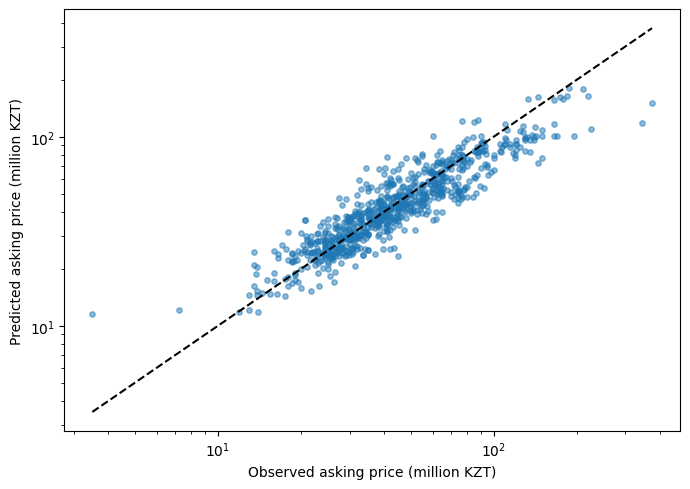

In [25]:
actual_prices = predictions['price'] / 1000000
predicted_prices = predictions[selected_model] / 1000000
plt.figure(figsize=(7, 5))
plt.scatter(actual_prices, predicted_prices, alpha=0.5, s=15)
minimum = min(actual_prices.min(), predicted_prices.min())
maximum = max(actual_prices.max(), predicted_prices.max())
plt.plot([minimum, maximum], [minimum, maximum], 'k--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Observed asking price (million KZT)')
plt.ylabel('Predicted asking price (million KZT)')
plt.tight_layout()
plt.savefig(output_folder / 'predictions.pdf')
plt.show()

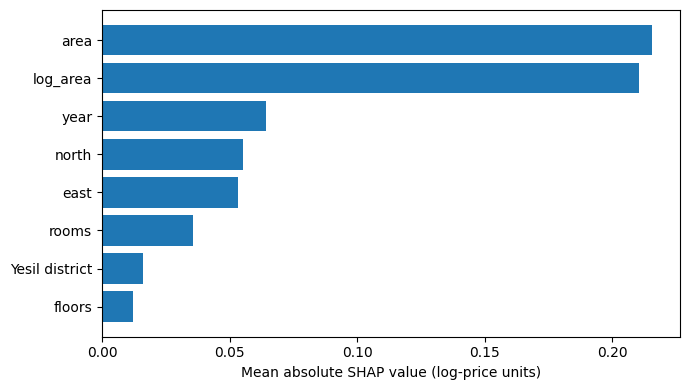

In [26]:
top_features = importance.head(8).iloc[::-1].copy()
top_features['feature'] = top_features['feature'].str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False)
top_features['feature'] = top_features['feature'].replace({'district_Есильский': 'Yesil district'})
plt.figure(figsize=(7, 4))
plt.barh(top_features['feature'], top_features['mean_absolute_SHAP'])
plt.xlabel('Mean absolute SHAP value (log-price units)')
plt.tight_layout()
plt.savefig(output_folder / 'shap.pdf')
plt.show()

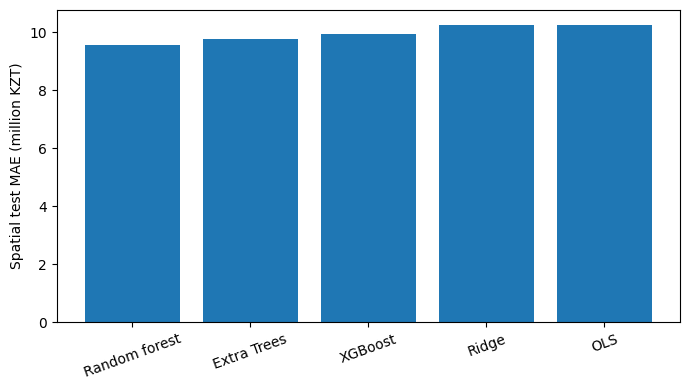

In [27]:
ordered_models = model_results.sort_values('MAE')
plt.figure(figsize=(7, 4))
plt.bar(ordered_models.index, ordered_models['MAE'] / 1000000)
plt.ylabel('Spatial test MAE (million KZT)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(output_folder / 'model_comparison.pdf')
plt.show()

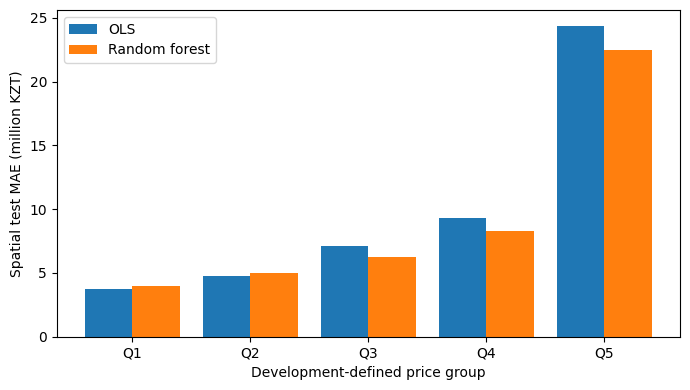

In [28]:
price_groups = group_results[group_results['group_type'] == 'price_group']
positions = np.arange(len(price_groups))
plt.figure(figsize=(7, 4))
plt.bar(positions - 0.2, price_groups['OLS_MAE'] / 1000000, width=0.4, label='OLS')
plt.bar(positions + 0.2, price_groups['model_MAE'] / 1000000, width=0.4, label=selected_model)
plt.xticks(positions, ['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
plt.xlabel('Development-defined price group')
plt.ylabel('Spatial test MAE (million KZT)')
plt.legend()
plt.tight_layout()
plt.savefig(output_folder / 'price_groups.pdf')
plt.show()

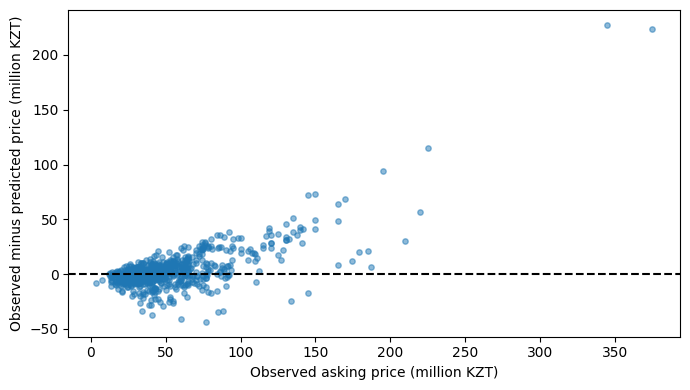

In [29]:
plt.figure(figsize=(7, 4))
plt.scatter(predictions['price'] / 1000000, predictions['signed_error'] / 1000000, alpha=0.5, s=15)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Observed asking price (million KZT)')
plt.ylabel('Observed minus predicted price (million KZT)')
plt.tight_layout()
plt.savefig(output_folder / 'errors.pdf')
plt.show()

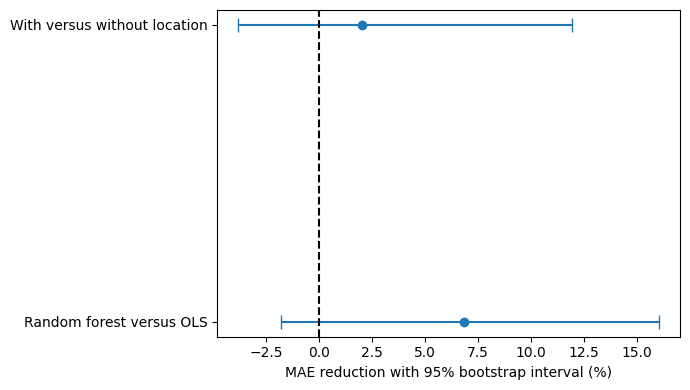

In [30]:
improvements = comparisons['MAE_reduction_percent'].to_numpy()
lower_errors = improvements - comparisons['CI_low'].to_numpy()
upper_errors = comparisons['CI_high'].to_numpy() - improvements
plt.figure(figsize=(7, 4))
plt.errorbar(improvements, [0, 1], xerr=[lower_errors, upper_errors], fmt='o', capsize=5)
plt.axvline(0, color='black', linestyle='--')
plt.yticks([0, 1], [selected_model + ' versus OLS', 'With versus without location'])
plt.xlabel('MAE reduction with 95% bootstrap interval (%)')
plt.tight_layout()
plt.savefig(output_folder / 'confidence_intervals.pdf')
plt.show()

In [31]:
predictions.to_csv(output_folder / 'predictions.csv', index=False)
model_results.to_csv(output_folder / 'model_results.csv')
validation_results.to_csv(output_folder / 'validation_results.csv', index=False)
comparisons.to_csv(output_folder / 'statistical_tests.csv')
group_results.to_csv(output_folder / 'group_results.csv', index=False)
importance.to_csv(output_folder / 'shap_importance.csv', index=False)
versions = {}
for package in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'shap', 'scipy', 'pyproj', 'matplotlib']:
    versions[package] = metadata.version(package)
display(pd.Series(versions, name='version'))
display(pd.DataFrame({'python': [platform.python_version()], 'system': [platform.platform()], 'processor': [platform.processor()], 'RAM_GiB': [psutil.virtual_memory().total / 1024 ** 3], 'runtime_seconds': [time.perf_counter() - start_time]}))
assert len(test_data) == 783
assert np.isclose(model_results.loc['Random forest', 'MAE'], 9558742.504041355, rtol=1e-08)
assert np.isclose(comparisons.iloc[0]['MAE_reduction_percent'], 6.825701024677586, rtol=1e-08)

numpy            2.3.5
pandas           3.0.1
scikit-learn     1.8.0
xgboost          3.1.3
shap            0.50.0
scipy           1.18.1
pyproj           3.7.2
matplotlib      3.10.8
Name: version, dtype: str

,python,system,processor,RAM_GiB,runtime_seconds
0,3.12.14,Windows-11-10.0.26200-SP0,"AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD",15.323029,111.957711
